In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit fastapi uvicorn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 42.2 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd

os.makedirs("demand_project", exist_ok=True)

rng = np.random.default_rng(42)
dates = pd.date_range("2023-01-01", periods=730, freq="D")

rows = []

for store in ["Store_A", "Store_B", "Store_C"]:
    for product in ["Product_A", "Product_B", "Product_C"]:
        base = rng.integers(30, 100)

        for date in dates:
            promotion = int(rng.random() < 0.15)
            holiday = int(date.dayofweek >= 5)

            weekly = 8 * np.sin(2 * np.pi * date.dayofweek / 7)
            yearly = 6 * np.sin(2 * np.pi * date.dayofyear / 365.25)

            units = (
                base + weekly + yearly
                + promotion * 15 + holiday * 5
                + rng.normal(0, 5)
            )

            rows.append([
                date, store, product,
                max(0, round(units)), promotion, holiday
            ])

df = pd.DataFrame(
    rows,
    columns=[
        "date", "store", "product",
        "units_sold", "promotion", "holiday"
    ]
)

df.to_csv("demand_project/retail_sales.csv", index=False)

print(df.shape)
display(df.head())

(6570, 6)


,date,store,product,units_sold,promotion,holiday
0,2023-01-01,Store_A,Product_A,39,0,1
1,2023-01-02,Store_A,Product_A,26,0,0
2,2023-01-03,Store_A,Product_A,43,0,0
3,2023-01-04,Store_A,Product_A,44,0,0
4,2023-01-05,Store_A,Product_A,44,0,0


In [3]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")

df = df.dropna(subset=["date", "store", "product", "units_sold"])
df = df.drop_duplicates(
    subset=["date", "store", "product"]
)

df["promotion"] = df["promotion"].fillna(0).astype(int)
df["holiday"] = df["holiday"].fillna(0).astype(int)

df = df.sort_values(["store", "product", "date"])

df.to_csv("demand_project/retail_sales_cleaned.csv", index=False)

print("Cleaning completed:", df.shape)

Cleaning completed: (6570, 6)


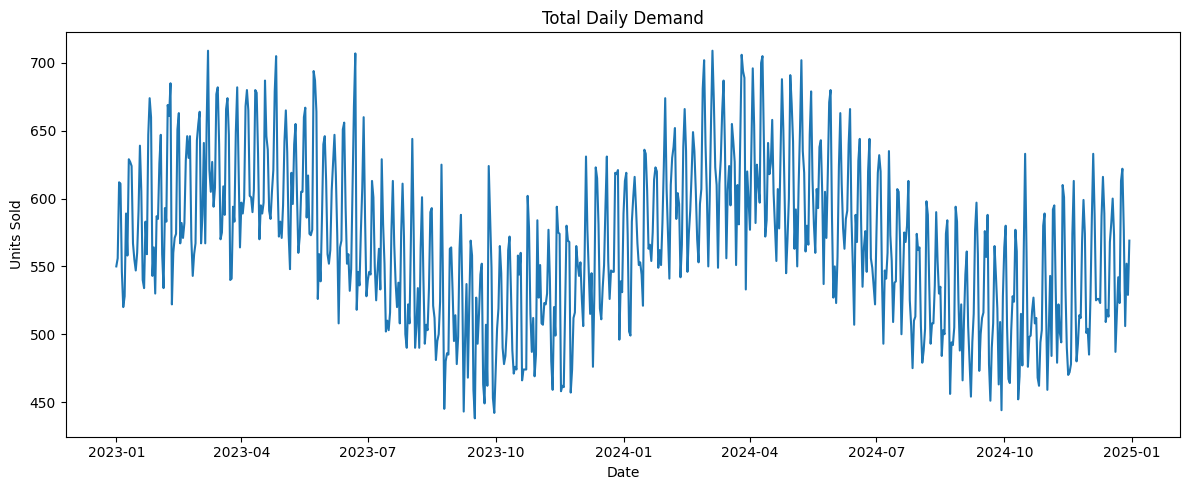

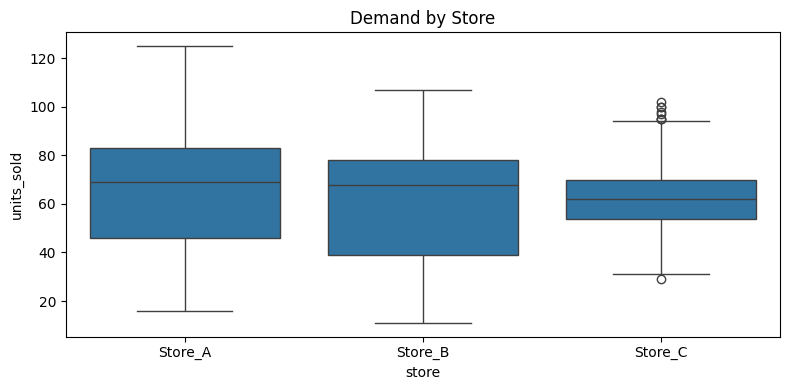

product
Product_A    47.310046
Product_B    75.648858
Product_C    66.371233
Name: units_sold, dtype: float64
            units_sold  promotion   holiday
units_sold    1.000000   0.270256 -0.113629
promotion     0.270256   1.000000  0.003638
holiday      -0.113629   0.003638  1.000000


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

daily = (
    df.groupby("date", as_index=False)["units_sold"]
      .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(daily["date"], daily["units_sold"])
plt.title("Total Daily Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.savefig("demand_project/demand_trend.png")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="store", y="units_sold")
plt.title("Demand by Store")
plt.tight_layout()
plt.savefig("demand_project/store_demand.png")
plt.show()

print(df.groupby("product")["units_sold"].mean())
print(df[["units_sold", "promotion", "holiday"]].corr())

In [5]:
df["dayofweek"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["dayofyear"] = df["date"].dt.dayofyear
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

group = df.groupby(["store", "product"])["units_sold"]

df["lag_1"] = group.shift(1)
df["lag_7"] = group.shift(7)
df["rolling_mean_7"] = group.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["rolling_std_7"] = group.transform(
    lambda s: s.shift(1).rolling(7).std()
)

df = df.dropna().reset_index(drop=True)

print(df.head())

        date    store    product  units_sold  promotion  holiday  dayofweek  \
0 2023-01-08  Store_A  Product_A          37          0        1          6   
1 2023-01-09  Store_A  Product_A          56          1        0          0   
2 2023-01-10  Store_A  Product_A          42          0        0          1   
3 2023-01-11  Store_A  Product_A          51          0        0          2   
4 2023-01-12  Store_A  Product_A          39          0        0          3   

   month  dayofyear  weekofyear  lag_1  lag_7  rolling_mean_7  rolling_std_7  
0      1          8           1   36.0   39.0       37.857143       6.718843  
1      1          9           2   37.0   26.0       37.571429       6.704654  
2      1         10           2   56.0   43.0       41.857143       7.603257  
3      1         11           2   42.0   44.0       41.714286       7.587584  
4      1         12           2   51.0   44.0       42.714286       8.360907  


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib

features = [
    "dayofweek", "month", "dayofyear", "weekofyear",
    "promotion", "holiday", "lag_1", "lag_7",
    "rolling_mean_7", "rolling_std_7"
]

df = pd.get_dummies(df, columns=["store", "product"])

categorical_features = [
    c for c in df.columns
    if c.startswith("store_") or c.startswith("product_")
]

features += categorical_features

cutoff = df["date"].max() - pd.Timedelta(days=30)

train = df[df["date"] <= cutoff].copy()
test = df[df["date"] > cutoff].copy()

X_train = train[features]
y_train = train["units_sold"]

X_test = test[features]
y_test = test["units_sold"]

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

nonzero = y_test != 0
mape = (
    np.mean(np.abs(
        (y_test[nonzero] - pred[nonzero]) / y_test[nonzero]
    )) * 100
    if nonzero.any() else np.nan
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE (%):", round(mape, 2))

MAE: 4.13
RMSE: 5.28
MAPE (%): 7.99


In [7]:
joblib.dump(model, "demand_project/demand_model.pkl")
joblib.dump(features, "demand_project/features.pkl")

df.to_csv("demand_project/model_data.csv", index=False)

print("Model saved!")

Model saved!


In [8]:
def forecast_next_day(store_name, product_name):
    history = df[
        (df[f"store_{store_name}"] == 1) &
        (df[f"product_{product_name}"] == 1)
    ].sort_values("date")

    if history.empty:
        return "Store or product not found"

    last = history.iloc[-1].copy()
    next_date = last["date"] + pd.Timedelta(days=1)

    row = last[features].copy()

    row["dayofweek"] = next_date.dayofweek
    row["month"] = next_date.month
    row["dayofyear"] = next_date.dayofyear
    row["weekofyear"] = int(next_date.isocalendar().week)

    row["lag_1"] = last["units_sold"]
    row["lag_7"] = history.iloc[-7]["units_sold"] if len(history) >= 7 else last["units_sold"]
    row["rolling_mean_7"] = history["units_sold"].tail(7).mean()
    row["rolling_std_7"] = history["units_sold"].tail(7).std()

    return max(0, round(model.predict(pd.DataFrame([row]))[0], 2))

print(forecast_next_day("Store_A", "Product_A"))

39.95


In [9]:
%%writefile demand_project/dashboard.py
import streamlit as st
import pandas as pd
import joblib
import numpy as np

st.title("Retail Demand Forecasting Dashboard")

data = pd.read_csv("demand_project/model_data.csv", parse_dates=["date"])
model = joblib.load("demand_project/demand_model.pkl")
features = joblib.load("demand_project/features.pkl")

store = st.selectbox("Select Store", ["Store_A", "Store_B", "Store_C"])
product = st.selectbox("Select Product", ["Product_A", "Product_B", "Product_C"])

history = data[
    (data[f"store_{store}"] == 1) &
    (data[f"product_{product}"] == 1)
].sort_values("date")

st.subheader("Historical Demand")
st.line_chart(history.set_index("date")["units_sold"])

if st.button("Predict Next Day"):
    last = history.iloc[-1].copy()
    next_date = last["date"] + pd.Timedelta(days=1)

    row = last[features].copy()
    row["dayofweek"] = next_date.dayofweek
    row["month"] = next_date.month
    row["dayofyear"] = next_date.dayofyear
    row["weekofyear"] = int(next_date.isocalendar().week)

    row["lag_1"] = last["units_sold"]
    row["lag_7"] = history.iloc[-7]["units_sold"]
    row["rolling_mean_7"] = history["units_sold"].tail(7).mean()
    row["rolling_std_7"] = history["units_sold"].tail(7).std()

    prediction = max(0, model.predict(pd.DataFrame([row]))[0])

    st.metric("Forecast Units", f"{prediction:.0f}")
    st.write("Forecast date:", next_date.date())

Writing demand_project/dashboard.py


In [10]:
%%writefile demand_project/api.py
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

app = FastAPI(title="Demand Forecast API")

model = joblib.load("demand_project/demand_model.pkl")
features = joblib.load("demand_project/features.pkl")

class PredictionInput(BaseModel):
    features: dict

@app.get("/")
def home():
    return {"message": "Demand Forecast API is running"}

@app.post("/predict")
def predict(data: PredictionInput):
    row = pd.DataFrame([data.features])
    row = row.reindex(columns=features, fill_value=0)
    prediction = max(0, float(model.predict(row)[0]))
    return {"predicted_units": prediction}

Writing demand_project/api.py


In [11]:
%%writefile demand_project/requirements.txt
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
streamlit
fastapi
uvicorn

Writing demand_project/requirements.txt


In [12]:
%%writefile demand_project/README.md
# Retail Demand Forecasting

## Run locally

Install dependencies:

pip install -r requirements.txt

Launch dashboard from the project root:

streamlit run demand_project/dashboard.py

Launch API:

uvicorn demand_project.api:app --reload

API documentation:

http://127.0.0.1:8000/docs

This project uses synthetic example retail data.
Replace it with real historical sales data before business use.

Writing demand_project/README.md


In [13]:
import zipfile
from google.colab import files

with zipfile.ZipFile(
    "Demand_Forecasting_Capstone.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for root, dirs, filenames in os.walk("demand_project"):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, arcname=path)

files.download("Demand_Forecasting_Capstone.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import os

for root, dirs, files in os.walk("demand_project"):
    for file in files:
        print(os.path.join(root, file))

demand_project/README.md
demand_project/retail_sales.csv
demand_project/model_data.csv
demand_project/retail_sales_cleaned.csv
demand_project/dashboard.py
demand_project/demand_trend.png
demand_project/api.py
demand_project/store_demand.png
demand_project/features.pkl
demand_project/demand_model.pkl
demand_project/requirements.txt


In [15]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

folder = "demand_project"
os.makedirs(folder, exist_ok=True)

clean_path = f"{folder}/retail_sales_cleaned.csv"
raw_path = f"{folder}/retail_sales.csv"

data_path = clean_path if os.path.exists(clean_path) else raw_path

df = pd.read_csv(data_path, parse_dates=["date"])
df = df.dropna(subset=["date", "store", "product", "units_sold"])
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")
df = df.dropna(subset=["units_sold"])
df = df.sort_values(["store", "product", "date"]).reset_index(drop=True)

df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

grouped = df.groupby(["store", "product"])["units_sold"]
df["lag_1"] = grouped.shift(1)
df["lag_7"] = grouped.shift(7)
df["rolling_mean_7"] = grouped.transform(
    lambda s: s.shift(1).rolling(7).mean()
)
df["rolling_std_7"] = grouped.transform(
    lambda s: s.shift(1).rolling(7).std()
)

df = df.dropna().reset_index(drop=True)

features = [
    "lag_1", "lag_7", "rolling_mean_7", "rolling_std_7",
    "promotion", "holiday", "day_of_week", "month"
]

cutoff = df["date"].max() - pd.Timedelta(days=30)
train = df[df["date"] <= cutoff].copy()
test = df[df["date"] > cutoff].copy()

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(train[features], train["units_sold"])
pred = model.predict(test[features])

def mape(y, p):
    y = np.asarray(y)
    p = np.asarray(p)
    mask = y != 0
    return np.mean(np.abs((y[mask] - p[mask]) / y[mask])) * 100 if mask.any() else np.nan

results = []

# Naive baseline: previous day's demand
for horizon in [1, 7, 30]:
    subset = test[test["date"] > cutoff + pd.Timedelta(days=30-horizon)]
    if subset.empty:
        continue

    actual = subset["units_sold"].to_numpy()
    rf_pred = model.predict(subset[features])

    naive_pred = subset["lag_1"].to_numpy()
    moving_pred = subset["rolling_mean_7"].to_numpy()

    for name, values in [
        ("Naive", naive_pred),
        ("Moving Average", moving_pred),
        ("Random Forest", rf_pred)
    ]:
        results.append({
            "Horizon": f"{horizon}-day window",
            "Model": name,
            "MAE": mean_absolute_error(actual, values),
            "RMSE": np.sqrt(mean_squared_error(actual, values)),
            "MAPE (%)": mape(actual, values)
        })

results_df = pd.DataFrame(results)
display(results_df.round(2))

joblib.dump(model, f"{folder}/demand_model.pkl")
joblib.dump(features, f"{folder}/features.pkl")
df.to_csv(f"{folder}/model_data.csv", index=False)
results_df.to_csv(f"{folder}/evaluation_results.csv", index=False)

print("Model and evaluation saved.")

,Horizon,Model,MAE,RMSE,MAPE (%)
0,1-day window,Naive,11.11,12.48,21.70
1,1-day window,Moving Average,4.05,4.85,8.51
2,1-day window,Random Forest,5.61,6.45,9.08
3,7-day window,Naive,9.33,11.80,17.95
4,7-day window,Moving Average,7.32,9.45,13.79
5,7-day window,Random Forest,4.12,5.25,7.74
6,30-day window,Naive,9.03,11.57,17.51
7,30-day window,Moving Average,6.89,8.79,13.35
8,30-day window,Random Forest,4.25,5.50,8.28


Model and evaluation saved.


In [16]:
%%writefile demand_project/dashboard.py
import os
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

BASE = os.path.dirname(os.path.abspath(__file__))

model = joblib.load(os.path.join(BASE, "demand_model.pkl"))
features = joblib.load(os.path.join(BASE, "features.pkl"))

data_path = os.path.join(BASE, "retail_sales_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join(BASE, "retail_sales.csv")

df = pd.read_csv(data_path, parse_dates=["date"])
df = df.dropna(subset=["date", "store", "product", "units_sold"])
df = df.sort_values("date")

def forecast(store, product, horizon):
    history = df[
        (df["store"] == store) &
        (df["product"] == product)
    ].sort_values("date").copy()

    if len(history) < 7:
        raise ValueError("இந்த Store/Product-க்கு குறைந்தது 7 நாட்கள் data தேவை.")

    values = history["units_sold"].astype(float).tolist()
    next_date = history["date"].max() + pd.Timedelta(days=1)
    predictions = []

    for i in range(horizon):
        date = next_date + pd.Timedelta(days=i)
        previous7 = values[-7:]

        row = {
            "lag_1": values[-1],
            "lag_7": values[-7],
            "rolling_mean_7": float(np.mean(previous7)),
            "rolling_std_7": float(np.std(previous7, ddof=1)),
            "promotion": 0,
            "holiday": int(date.dayofweek >= 5),
            "day_of_week": date.dayofweek,
            "month": date.month
        }

        x = pd.DataFrame([row])[features]
        prediction = max(0, float(model.predict(x)[0]))

        predictions.append({
            "date": date,
            "forecast_demand": round(prediction, 2)
        })
        values.append(prediction)

    return pd.DataFrame(predictions), history

st.title("Retail Demand Forecasting Dashboard")
st.write("Select a store, product and forecast period.")

stores = sorted(df["store"].astype(str).unique())
products = sorted(df["product"].astype(str).unique())

store = st.selectbox("Select Store", stores)
product = st.selectbox("Select Product", products)
horizon = st.selectbox("Forecast Horizon (days)", [1, 7, 30])

if st.button("Forecast Demand"):
    try:
        forecast_df, history = forecast(store, product, horizon)

        st.subheader("Forecast Results")
        st.dataframe(forecast_df, use_container_width=True)

        st.metric(
            "Total Forecast Demand",
            round(forecast_df["forecast_demand"].sum(), 2)
        )

        fig, ax = plt.subplots(figsize=(10, 4))
        recent = history.tail(30)
        ax.plot(recent["date"], recent["units_sold"], label="Actual Demand")
        ax.plot(
            forecast_df["date"],
            forecast_df["forecast_demand"],
            marker="o",
            label="Forecast"
        )
        ax.set_xlabel("Date")
        ax.set_ylabel("Units Sold")
        ax.legend()
        fig.autofmt_xdate()
        st.pyplot(fig)

        st.download_button(
            "Download Forecast CSV",
            forecast_df.to_csv(index=False),
            file_name="demand_forecast.csv",
            mime="text/csv"
        )
    except Exception as e:
        st.error(str(e))

Overwriting demand_project/dashboard.py


In [17]:
%%writefile demand_project/api.py
import os
import joblib
import numpy as np
import pandas as pd

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

BASE = os.path.dirname(os.path.abspath(__file__))

model = joblib.load(os.path.join(BASE, "demand_model.pkl"))
features = joblib.load(os.path.join(BASE, "features.pkl"))

data_path = os.path.join(BASE, "retail_sales_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join(BASE, "retail_sales.csv")

df = pd.read_csv(data_path, parse_dates=["date"])

app = FastAPI(title="Demand Forecasting API")

class ForecastRequest(BaseModel):
    store: str
    product: str
    horizon: int = Field(default=7, ge=1, le=30)

@app.get("/")
def home():
    return {"message": "Demand Forecasting API is running"}

@app.post("/predict")
def predict(request: ForecastRequest):
    history = df[
        (df["store"] == request.store) &
        (df["product"] == request.product)
    ].sort_values("date")

    if len(history) < 7:
        raise HTTPException(
            status_code=400,
            detail="At least 7 days of history are required."
        )

    values = history["units_sold"].astype(float).tolist()
    start_date = history["date"].max() + pd.Timedelta(days=1)
    output = []

    for i in range(request.horizon):
        date = start_date + pd.Timedelta(days=i)
        previous7 = values[-7:]

        row = {
            "lag_1": values[-1],
            "lag_7": values[-7],
            "rolling_mean_7": float(np.mean(previous7)),
            "rolling_std_7": float(np.std(previous7, ddof=1)),
            "promotion": 0,
            "holiday": int(date.dayofweek >= 5),
            "day_of_week": date.dayofweek,
            "month": date.month
        }

        x = pd.DataFrame([row])[features]
        value = max(0, float(model.predict(x)[0]))
        output.append({
            "date": date.strftime("%Y-%m-%d"),
            "forecast_demand": round(value, 2)
        })
        values.append(value)

    return {
        "store": request.store,
        "product": request.product,
        "horizon_days": request.horizon,
        "forecast": output
    }

Overwriting demand_project/api.py


In [18]:
%%writefile demand_project/requirements.txt
pandas
numpy
matplotlib
scikit-learn
joblib
streamlit
fastapi
uvicorn

Overwriting demand_project/requirements.txt


In [19]:
import os

for root, dirs, filenames in os.walk("demand_project"):
    for filename in sorted(filenames):
        print(os.path.join(root, filename))

demand_project/README.md
demand_project/api.py
demand_project/dashboard.py
demand_project/demand_model.pkl
demand_project/demand_trend.png
demand_project/evaluation_results.csv
demand_project/features.pkl
demand_project/model_data.csv
demand_project/requirements.txt
demand_project/retail_sales.csv
demand_project/retail_sales_cleaned.csv
demand_project/store_demand.png


In [20]:
import os
import zipfile
from google.colab import files

zip_name = "Demand_Forecasting_Capstone.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as z:
    for root, dirs, filenames in os.walk("demand_project"):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, arcname=path)

print("Final project ZIP created!")
files.download(zip_name)

Final project ZIP created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/demand_project
!streamlit run dashboard.py --server.port 8501

/content/demand_project


2026-10-20 13:32:21.641 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.70.111.28:8501



In [ ]:
%cd /content/demand_project
!streamlit run dashboard.py --server.port 8501